# Prova – ETL e Visualização de Dados: Rede de Oficinas Automotivas

**Cenário:** sou Analista de Dados Júnior de uma rede de oficinas. A empresa enviou uma planilha Excel com **50.000 registros de serviços**, mas a base tem problemas de qualidade (linhas vazias, cidades escritas de jeitos diferentes, valores com "R$", datas inválidas, duplicados e quantidades negativas).

**Fluxo seguido:** IMPORTAR → LIMPAR → PADRONIZAR → ANALISAR → VISUALIZAR

Ferramentas: **Python**, **Pandas** (tabelas) e **Matplotlib** (gráficos).

---
## PARTE 1 – Importação e exploração dos dados

### 1. Importar as bibliotecas
- `pandas` (apelido `pd`): biblioteca para ler e manipular tabelas (DataFrames).
- `matplotlib.pyplot` (apelido `plt`): biblioteca para criar gráficos.

In [1]:
# Importa a biblioteca pandas
import pandas as pd
# Importa o matplotlib para criar os gráficos
import matplotlib.pyplot as plt

### 2. Caminho do arquivo Excel
O `r` antes das aspas significa *raw string*: faz o Python ler as barras `\` do caminho do Windows sem confundi-las com comandos especiais.

> Se o arquivo estiver na mesma pasta do notebook, basta o nome dele. Se estiver em outra pasta, troque pelo caminho completo (ex.: `r"C:\Users\SeuUsuario\Downloads\Dataset_Prova_Oficinas_50mil.xlsx"`).

In [2]:
# Caminho do arquivo (pasta data/ do repositório)
arquivo = r"data/Dataset_Prova_Oficinas_50mil.xlsx"

### 3. Ler a planilha
`pd.read_excel()` lê o Excel e cria o DataFrame `df`. O parâmetro `sheet_name="Servicos"` indica qual aba da planilha será lida.

In [3]:
# Lê a planilha
df = pd.read_excel(arquivo, sheet_name="Servicos")

### 4. Primeiros registros
`df.head()` mostra as 5 primeiras linhas. Já dá para ver alguns problemas: a primeira linha está toda vazia, cidades em maiúsculas/minúsculas e valores com "R$".

In [4]:
# Mostra as primeiras linhas (por padrão, as 5 primeiras)
print("Impressão das primeiras linhas:")
df.head()

Impressão das primeiras linhas:


,id_ordem,data_servico,cliente,cidade,oficina,categoria,servico,tipo_veiculo,valor_servico,quantidade,forma_pagamento
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,OS000002,05/09/2026,Cliente 000002,CEILÂNDIA,Auto Center Central,Ar-condicionado,Higienização do Ar,Picape,"144,84",2.0,PIX
2,OS000003,07/03/2025,Cliente 000003,Águas Claras,Auto Center Sul,Elétrica,Motor de Partida,Hatch,"778,53",1.0,Cartão de Débito
3,OS000004,20/05/2025,Cliente 000004,ÁGUAS CLARAS,Auto Center Central,Pneus e Rodas,Alinhamento,SUV,"R$ 99,43",2.0,Cartão de Crédito
4,OS000005,08/12/2025,Cliente 000005,Samambaia,Oficina Prime,Manutenção Preventiva,Troca de Óleo,Picape,"391,80",1.0,PIX


### 5. Quantidade de linhas e colunas
`df.shape` devolve **(linhas, colunas)**.

In [5]:
# Mostra a dimensão do DataFrame
print("Tamanho do DataFrame (linhas, colunas):", df.shape)

Tamanho do DataFrame (linhas, colunas): (50000, 11)


### 6. Nomes das colunas
`df.columns` lista o nome de todas as colunas.

In [6]:
# Mostra os nomes das colunas
print(df.columns)

Index(['id_ordem', 'data_servico', 'cliente', 'cidade', 'oficina', 'categoria',
       'servico', 'tipo_veiculo', 'valor_servico', 'quantidade',
       'forma_pagamento'],
      dtype='str')


---
## PARTE 2 – Tratamento dos dados (ETL)

### 1. Remover linhas totalmente vazias
`dropna(how="all")` apaga apenas as linhas em que **todas** as colunas estão vazias (NaN). Linhas com só alguns campos vazios continuam.

In [7]:
# Remove linhas onde TODAS as colunas estão vazias
print("Linhas antes:", df.shape[0])
df = df.dropna(how="all")
print("Linhas depois de remover as vazias:", df.shape[0])

Linhas antes: 50000
Linhas depois de remover as vazias: 49700


### 2. Padronizar a coluna `cidade`
A mesma cidade aparece escrita de várias formas: `" Brasília "`, `"BRASÍLIA"`, `"brasília"`...
- `astype("string")` → garante que a coluna é texto.
- `str.strip()` → remove espaços extras no início e no fim.
- `str.lower().str.title()` → deixa tudo minúsculo e depois coloca a primeira letra de cada palavra em maiúscula (`"Águas Claras"`).

In [8]:
# Converte para texto
df["cidade"] = df["cidade"].astype("string")
# Remove espaços extras
df["cidade"] = df["cidade"].str.strip()
# Coloca todas no mesmo formato (primeira letra maiúscula)
df["cidade"] = df["cidade"].str.lower().str.title()

# Confere: agora cada cidade aparece uma única vez
print(df["cidade"].value_counts())

cidade
Brasília        16842
Taguatinga       9475
Ceilândia        7441
Águas Claras     4937
Samambaia        3981
Gama             2979
Guará            2543
Sobradinho       1502
Name: count, dtype: Int64


### 3. Tratar a coluna `valor_servico`
Os valores estão como texto no padrão brasileiro, alguns com "R$" (ex.: `"R$ 1.118,50"`). O Python só entende números no padrão americano (`1118.50`), então:
1. remove o `"R$"`;
2. remove o ponto de milhar `"."`;
3. troca a vírgula decimal `","` por ponto `"."`;
4. `str.strip()` tira o espaço que sobrou.

`regex=False` diz ao Pandas para tratar o texto literalmente (sem interpretar `$` e `.` como símbolos especiais).

In [9]:
# Transforma a coluna em texto
df["valor_servico"] = df["valor_servico"].astype("string")
# Remove símbolo de moeda, ponto de milhar e troca vírgula por ponto
df["valor_servico"] = (
    df["valor_servico"]
    .str.replace("R$", "", regex=False)
    .str.replace(".", "", regex=False)
    .str.replace(",", ".", regex=False)
    .str.strip()
)
print(df["valor_servico"].head(10))

1      144.84
2      778.53
3       99.43
4      391.80
5     1118.50
6     2178.82
7      265.86
8      399.42
9      272.83
10     114.43
Name: valor_servico, dtype: string


### 4. Converter `valor_servico` para número
`pd.to_numeric()` transforma o texto em número. Com `errors="coerce"`, se algum valor não puder ser convertido ele vira NaN (vazio) em vez de dar erro.

In [10]:
# Converte a coluna de valor para o formato numérico
df["valor_servico"] = pd.to_numeric(df["valor_servico"], errors="coerce")
print(df["valor_servico"].head(10))
print("Tipo da coluna:", df["valor_servico"].dtype)

1      144.84
2      778.53
3       99.43
4       391.8
5      1118.5
6     2178.82
7      265.86
8      399.42
9      272.83
10     114.43
Name: valor_servico, dtype: Float64
Tipo da coluna: Float64


### 5 e 6. Converter `data_servico` para data (datas inválidas viram nulo)
- `pd.to_datetime()` converte texto em data.
- `dayfirst=True` → as datas estão no formato brasileiro **dia/mês/ano**.
- `errors="coerce"` → textos como `"data inválida"` viram **NaT** (valor nulo de data).

In [11]:
# Converte a coluna de data; datas inválidas viram nulas (NaT)
df["data_servico"] = pd.to_datetime(df["data_servico"], errors="coerce", dayfirst=True)
print("Datas inválidas (transformadas em nulo):", df["data_servico"].isna().sum())
print(df["data_servico"].head())

Datas inválidas (transformadas em nulo): 800
1   2026-09-05
2   2025-03-07
3   2025-05-20
4   2025-12-08
5   2026-08-29
Name: data_servico, dtype: datetime64[us]


### 7. Identificar registros duplicados
`df.duplicated()` marca como `True` cada linha que é cópia idêntica de outra. O `.sum()` conta quantos `True` existem.

In [12]:
# Mostra a quantidade de duplicados
print("Duplicados:", df.duplicated().sum())

Duplicados: 645


### 8. Remover os duplicados
`drop_duplicates()` mantém a primeira ocorrência e apaga as cópias.

In [13]:
# Remove os duplicados
df = df.drop_duplicates()
print("Duplicados após remoção:", df.duplicated().sum())
print("Tamanho após remover duplicados:", df.shape)

Duplicados após remoção: 0
Tamanho após remover duplicados: (49055, 11)


### 9. Tratar valores negativos em `quantidade`
Não existe quantidade negativa de serviço. Os negativos da base são **-1, -2 e -3**, os mesmos números das quantidades normais só com o sinal errado — parece erro de digitação do sinal.

Por isso, usei `.abs()` (valor absoluto), que transforma `-2` em `2`, mantendo a informação.
> Na revisão foi usado `df.loc[df["quantidade"] < 0, "quantidade"] = 0`, que troca os negativos por 0. Também é válido, mas assim o serviço ficaria com quantidade zero.

In [14]:
# Identifica os valores negativos
print("Quantidades negativas:", (df["quantidade"] < 0).sum())

# Corrige os negativos (transforma em positivo)
df["quantidade"] = df["quantidade"].abs()

print("Quantidades negativas após o tratamento:", (df["quantidade"] < 0).sum())

Quantidades negativas: 581
Quantidades negativas após o tratamento: 0


### 10. Primeiros registros após o ETL
Agora as cidades estão padronizadas, os valores são números e as datas estão no formato de data.

In [15]:
# Mostra o resultado final do ETL
print("Formato final:", df.shape)
print(df.dtypes)
df.head()

Formato final: (49055, 11)
id_ordem                      str
data_servico       datetime64[us]
cliente                       str
cidade                     string
oficina                       str
categoria                     str
servico                       str
tipo_veiculo                  str
valor_servico             Float64
quantidade                float64
forma_pagamento               str
dtype: object


,id_ordem,data_servico,cliente,cidade,oficina,categoria,servico,tipo_veiculo,valor_servico,quantidade,forma_pagamento
1,OS000002,2026-09-05,Cliente 000002,Ceilândia,Auto Center Central,Ar-condicionado,Higienização do Ar,Picape,144.84,2.0,PIX
2,OS000003,2025-03-07,Cliente 000003,Águas Claras,Auto Center Sul,Elétrica,Motor de Partida,Hatch,778.53,1.0,Cartão de Débito
3,OS000004,2025-05-20,Cliente 000004,Águas Claras,Auto Center Central,Pneus e Rodas,Alinhamento,SUV,99.43,2.0,Cartão de Crédito
4,OS000005,2025-12-08,Cliente 000005,Samambaia,Oficina Prime,Manutenção Preventiva,Troca de Óleo,Picape,391.8,1.0,PIX
5,OS000006,2026-08-29,Cliente 000006,Ceilândia,Auto Center Central,Elétrica,Alternador,Utilitário,1118.5,3.0,Boleto


---
## PARTE 3 – Gráfico: serviços por categoria
**Pergunta:** Qual categoria possui a maior quantidade de serviços realizados?

`value_counts()` conta quantas vezes cada categoria aparece (já em ordem decrescente) e `plot(kind="bar")` cria o gráfico de barras.

categoria
Manutenção Preventiva    17634
Mecânica                 12215
Elétrica                  6975
Pneus e Rodas             5348
Ar-condicionado           3929
Funilaria e Pintura       2954
Name: count, dtype: int64


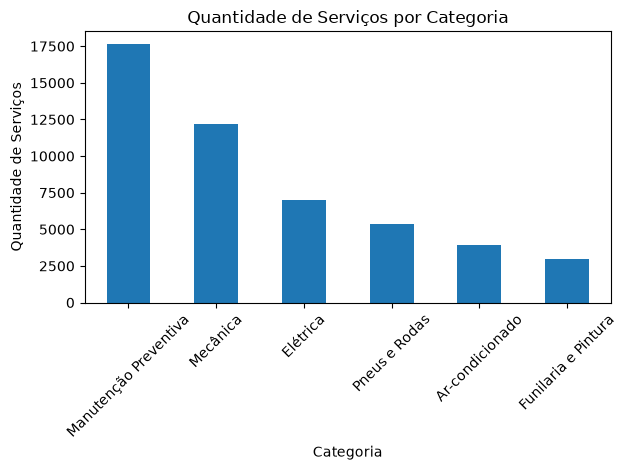

In [16]:
# Conta os serviços por categoria
quantidade = df["categoria"].value_counts()
# Mostra o resultado antes de criar o gráfico
print(quantidade)
# Cria o gráfico de barras
quantidade.plot(kind="bar")
# Define o título
plt.title("Quantidade de Serviços por Categoria")
# Nome do eixo X
plt.xlabel("Categoria")
# Nome do eixo Y
plt.ylabel("Quantidade de Serviços")
# Rotaciona os nomes para não encavalar
plt.xticks(rotation=45)
# Organiza o gráfico
plt.tight_layout()
# Exibe o gráfico
plt.show()

**Resposta:** a categoria **Manutenção Preventiva** é a que tem mais serviços realizados, seguida de **Mecânica**.

---
## PARTE 4 – Gráfico: serviços realizados
**Pergunta:** Quais são os serviços mais realizados pela rede de oficinas?

Como são muitos serviços, usei `figsize=(12, 6)` para deixar o gráfico mais largo e `rotation=90` para os nomes ficarem legíveis.

servico
Troca de Óleo                  7989
Revisão Geral                  5238
Troca de Pastilhas de Freio    4297
Troca de Correia               2991
Troca de Bateria               2936
Troca de Filtros               2655
Suspensão                      2491
Higienização do Ar             1973
Diagnóstico Elétrico           1910
Alinhamento                    1879
Embreagem                      1816
Alinhamento Preventivo         1752
Balanceamento                  1561
Recarga de Gás                 1365
Alternador                     1281
Troca de Pneus                 1195
Pintura Parcial                1138
Martelinho de Ouro              905
Motor de Partida                848
Reparo de Pneu                  713
Reparo de Para-choque           658
Retífica de Motor               620
Reparo do Compressor            591
Pintura Completa                253
Name: count, dtype: int64


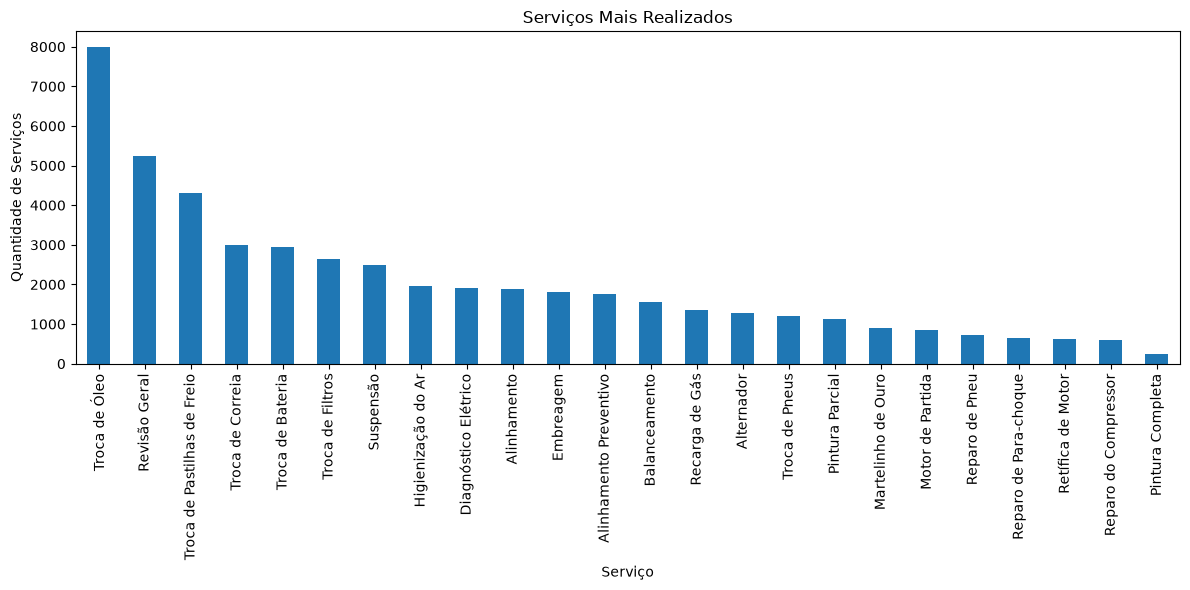

In [17]:
# Conta quantas vezes cada serviço foi realizado
quantidade = df["servico"].value_counts()
# Mostra o resultado antes de criar o gráfico
print(quantidade)
# Cria o gráfico de barras (mais largo, pois são muitos serviços)
quantidade.plot(kind="bar", figsize=(12, 6))
# Define o título
plt.title("Serviços Mais Realizados")
# Nome do eixo X
plt.xlabel("Serviço")
# Nome do eixo Y
plt.ylabel("Quantidade de Serviços")
# Rotaciona os nomes
plt.xticks(rotation=90)
# Organiza o gráfico
plt.tight_layout()
# Exibe o gráfico
plt.show()

**Resposta:** os serviços mais realizados são **Troca de Óleo**, **Revisão Geral** e **Troca de Pastilhas de Freio**.

---
## PARTE 5 – Gráfico: serviços por cidade
**Pergunta:** Em quais cidades ocorre a maior quantidade de serviços?

Esse gráfico só fica correto porque a coluna `cidade` foi padronizada na Parte 2 — sem isso, "Brasília" e "BRASÍLIA" apareceriam como barras separadas.

cidade
Brasília        16615
Taguatinga       9355
Ceilândia        7355
Águas Claras     4871
Samambaia        3935
Gama             2944
Guará            2504
Sobradinho       1476
Name: count, dtype: Int64


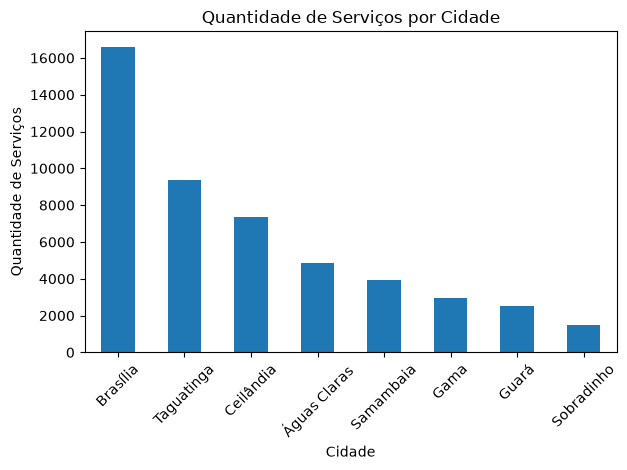

In [18]:
# Serviços por cidade
quantidade = df["cidade"].value_counts()
# Mostra o resultado antes de criar o gráfico
print(quantidade)
# Cria o gráfico de barras
quantidade.plot(kind="bar")
# Define o título
plt.title("Quantidade de Serviços por Cidade")
# Nome do eixo X
plt.xlabel("Cidade")
# Nome do eixo Y
plt.ylabel("Quantidade de Serviços")
# Ajusta os nomes das cidades
plt.xticks(rotation=45)
# Organiza o gráfico
plt.tight_layout()
# Exibe o gráfico
plt.show()

**Resposta:** **Brasília** concentra a maior quantidade de serviços, seguida de **Taguatinga** e **Ceilândia**.

---
## PARTE 6 – Gráfico: formas de pagamento
**Pergunta:** Qual é a forma de pagamento mais utilizada pelos clientes?

**Tipo escolhido: gráfico de pizza.** Como são poucas opções (5 formas de pagamento), a pizza mostra bem a **participação (%)** de cada uma no total.
- `autopct="%1.1f%%"` escreve a porcentagem em cada fatia com 1 casa decimal.
- `plt.ylabel("")` remove o nome que o Pandas coloca automaticamente na lateral da pizza.

forma_pagamento
PIX                  18651
Cartão de Crédito    14281
Cartão de Débito      8309
Dinheiro              4889
Boleto                2925
Name: count, dtype: int64


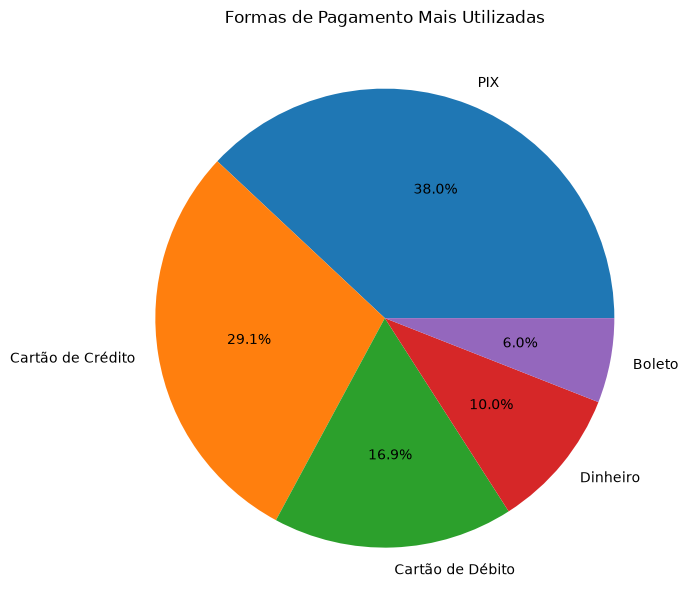

In [19]:
# Conta as formas de pagamento
quantidade = df["forma_pagamento"].value_counts()
# Mostra o resultado antes de criar o gráfico
print(quantidade)
# Cria o gráfico de pizza com a porcentagem de cada fatia
quantidade.plot(kind="pie", autopct="%1.1f%%", figsize=(7, 7))
# Define o título
plt.title("Formas de Pagamento Mais Utilizadas")
# Remove o nome automático do eixo Y
plt.ylabel("")
# Organiza o gráfico
plt.tight_layout()
# Exibe o gráfico
plt.show()

**Resposta:** o **PIX** é a forma de pagamento mais utilizada (cerca de 38%), seguido do **Cartão de Crédito** (cerca de 29%).

---
## PARTE 7 – Desafio

### Gráfico 7.1 – Faturamento por oficina

**Pergunta:** Qual oficina da rede gera o maior faturamento?

**Gráfico:** barras horizontais (`kind="barh"`). Os nomes das oficinas são longos e ficam mais fáceis de ler na horizontal.

**Como foi calculado:**
1. Criei a coluna `faturamento` = `valor_servico` × `quantidade`.
2. `groupby("oficina")` agrupa as linhas por oficina e `["faturamento"].sum()` soma o faturamento de cada uma.
3. `sort_values()` ordena do menor para o maior (assim a maior barra fica no topo).
4. No gráfico, dividi por 1.000.000 para mostrar em **milhões de R$** (senão o Matplotlib usa notação científica, tipo `1e7`, que é difícil de ler).

oficina
Oficina Express         5010615.76
Oficina Prime           7775398.74
Auto Center Sul         9623295.43
Auto Center Norte      12800070.26
Auto Center Central    18794360.37
Name: faturamento, dtype: Float64


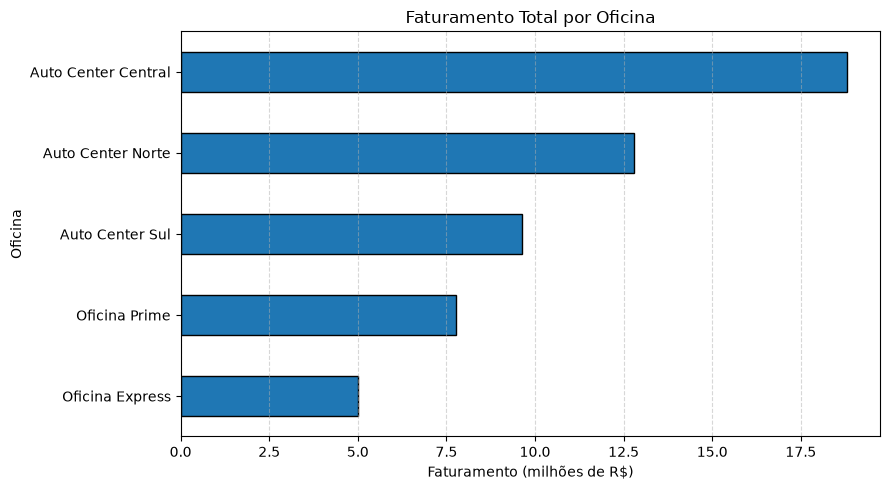

In [20]:
# Cria a coluna de faturamento (valor x quantidade)
df["faturamento"] = df["valor_servico"] * df["quantidade"]

# Soma o faturamento de cada oficina e ordena
faturamento = df.groupby("oficina")["faturamento"].sum().sort_values()

# Mostra o resultado
print(faturamento)

# Cria o gráfico de barras horizontais
(faturamento / 1000000).plot(kind="barh", figsize=(9, 5), edgecolor="black")

# Título e nomes dos eixos
plt.title("Faturamento Total por Oficina")
plt.xlabel("Faturamento (milhões de R$)")
plt.ylabel("Oficina")

# Adiciona uma grade no eixo X para facilitar a leitura
plt.grid(axis="x", linestyle="--", alpha=0.5)

# Organiza e exibe
plt.tight_layout()
plt.show()

**Conclusão:** o **Auto Center Central** é a oficina com maior faturamento (cerca de R$ 18,8 milhões), bem à frente do **Auto Center Norte** (cerca de R$ 12,8 milhões). A **Oficina Express** tem o menor faturamento (cerca de R$ 5 milhões). O faturamento acompanha o volume de serviços: a oficina que mais atende é a que mais fatura.

### Gráfico 7.2 – Serviços por mês

**Pergunta:** A quantidade de serviços varia muito ao longo dos meses?

**Gráfico:** linha (`kind="line"`), o tipo mais adequado para mostrar a evolução ao longo do tempo.

**Como foi calculado:**
- `df["data_servico"].dt.strftime("%Y-%m")` transforma cada data em um texto com **ano-mês** (ex.: `2025-03`). O `.dt` dá acesso às funções de data; `%Y` é o ano e `%m` é o mês.
- `value_counts().sort_index()` conta os serviços de cada mês e ordena em ordem cronológica.
- As datas inválidas (NaT) ficam de fora automaticamente.

mes
2025-01    2365
2025-02    2175
2025-03    2395
2025-04    2342
2025-05    2401
2025-06    2356
2025-07    2373
2025-08    2468
2025-09    2298
2025-10    2436
2025-11    2270
2025-12    2364
2026-01    2331
2026-02    2216
2026-03    2434
2026-04    2300
2026-05    2400
2026-06    2349
2026-07    2456
2026-08    2391
2026-09    1145
Name: count, dtype: int64


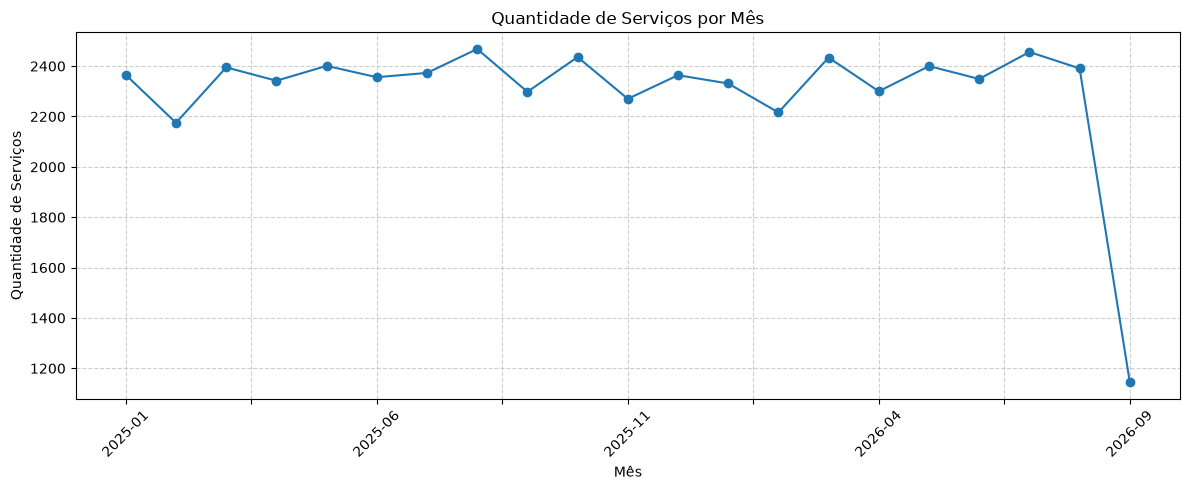

In [21]:
# Cria uma coluna com o mês/ano de cada serviço
df["mes"] = df["data_servico"].dt.strftime("%Y-%m")

# Conta os serviços por mês, em ordem cronológica
por_mes = df["mes"].value_counts().sort_index()

# Mostra o resultado
print(por_mes)

# Cria o gráfico de linha com marcadores nos pontos
por_mes.plot(kind="line", marker="o", figsize=(12, 5))

# Título e nomes dos eixos
plt.title("Quantidade de Serviços por Mês")
plt.xlabel("Mês")
plt.ylabel("Quantidade de Serviços")

# Rotaciona os meses e adiciona grade
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.6)

# Organiza e exibe
plt.tight_layout()
plt.show()

**Conclusão:** a demanda é **estável** ao longo do período, entre cerca de **2.200 e 2.500 serviços por mês**, sem um pico sazonal forte. A queda em **setembro/2026** não indica uma redução real: a base só vai até **15/09/2026**, ou seja, o mês está incompleto, então esse ponto não deve ser comparado com os outros.